# Chapter 4 — Training Models: Practice Notebook
## Part 1: Linear Regression & Analytical Solutions (Hands-On Lab)

In this notebook, we verify how the mathematical theory translates into real code and outputs.
Every section includes:
1. **What we are doing and why**
2. **What the code does**
3. **What the output means**
4. **How this output reinforces the concepts for interviews**

---
### Step 1: Simulating a Real-World Problem with Known Ground Truth

In real machine learning projects, you never know the true underlying function.  
To verify whether our training algorithms actually work, we simulate a dataset where **we control the secret ground truth**:

$$y = 4 + 3x + \text{Gaussian Noise}$$

- **True Bias ($\theta_0$)**: `4` (where the line hits y when $x=0$)
- **True Weight ($\theta_1$)**: `3` (for every 1 unit of $x$, $y$ increases by 3)
- **Gaussian Noise**: Random imperfections added so data points don't sit on a fake, perfect line.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Set seed for exact reproducibility
np.random.seed(42)

# Generate 100 random feature values between 0 and 2
X = 2 * np.random.rand(100, 1)

# Generate targets using y = 4 + 3x + Gaussian noise (mean 0, std 1)
y = 4 + 3 * X + np.random.randn(100, 1)

print("Generated X shape:", X.shape)
print("Generated y shape:", y.shape)
print("\nFirst 3 X values:\n", X[:3])
print("\nFirst 3 y values:\n", y[:3])

Generated X shape: (100, 1)
Generated y shape: (100, 1)

First 3 X values:
 [[0.74908024]
 [1.90142861]
 [1.46398788]]

First 3 y values:
 [[6.33428778]
 [9.40527849]
 [8.48372443]]


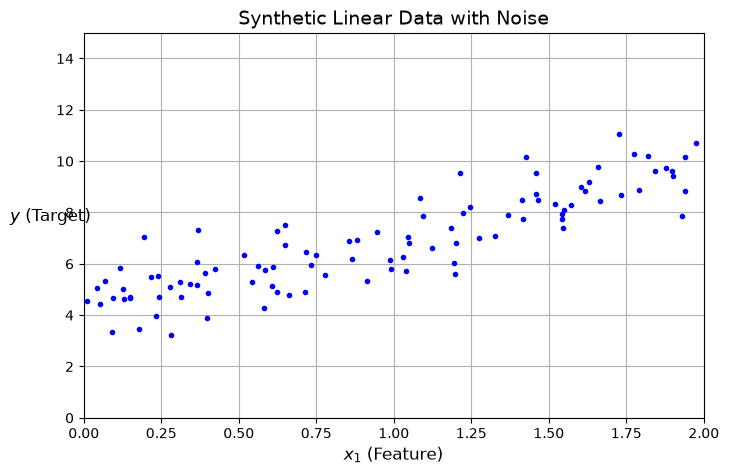

In [2]:
# Visualize the dataset
plt.figure(figsize=(8, 5))
plt.plot(X, y, "b.")
plt.xlabel("$x_1$ (Feature)", fontsize=12)
plt.ylabel("$y$ (Target)", rotation=0, fontsize=12)
plt.title("Synthetic Linear Data with Noise", fontsize=14)
plt.axis([0, 2, 0, 15])
plt.grid(True)
plt.show()

🔍 **What the plot shows & how it reinforces understanding**:
- The data points clearly trend upwards with a positive slope, but they are scattered due to the noise.
- If you were drawing a line through this with a ruler, you would aim for the center of the cloud.
- **Our Goal**: Use math to find the exact optimal line that minimizes Mean Squared Error (MSE).

---
### Step 2: Finding the Best Line with The Normal Equation

The **Normal Equation** is:
$$\hat{\mathbf{\theta}} = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}$$

**Why do we do `np.c_[np.ones(...), X]`?**
Because we need a dummy feature $x_0 = 1$ for the bias term $\theta_0$.
- Matrix `X` had shape `(100, 1)`.
- Matrix `X_b` will have shape `(100, 2)`: column 0 is all 1s, column 1 is our $x_1$ values.

In [3]:
# Add x0 = 1 column to each instance
X_b = np.c_[np.ones((100, 1)), X]
print("Shape of X_b:", X_b.shape)
print("First 3 rows of X_b (notice column 0 is all 1s):\n", X_b[:3])

# Calculate optimal theta in one step using the Normal Equation
# Using @ for matrix dot product and np.linalg.inv for matrix inversion
theta_best = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

print("\n--- Model Parameters Learned ---")
print("Estimated theta_0 (Intercept):", theta_best[0][0])
print("Estimated theta_1 (Slope):    ", theta_best[1][0])

Shape of X_b: (100, 2)
First 3 rows of X_b (notice column 0 is all 1s):
 [[1.         0.74908024]
 [1.         1.90142861]
 [1.         1.46398788]]

--- Model Parameters Learned ---
Estimated theta_0 (Intercept): 4.21509615754675
Estimated theta_1 (Slope):     2.7701133864384806


🔍 **What this output means & how it reinforces understanding**:
- **The Secret Ground Truth**: $\theta_0 = 4$, $\theta_1 = 3$.
- **The Model's Output**: $\theta_0 \approx 4.215$, $\theta_1 \approx 2.770$.
- **Why isn't it exactly 4 and 3?** Because of the random Gaussian noise! The model cannot know the noise-free function; it found the mathematically optimal weights for the noisy data we gave it.
- **Key Takeaway**: Without any loops, epochs, or learning rates, the formula solved the problem directly in one shot!

---
### Step 3: Making Predictions & Visualizing the Fitted Line

Now that we have $\hat{\mathbf{\theta}}$, how does the model predict for new instances?
$$\hat{y} = \mathbf{X}_{\text{new\_b}} \times \hat{\mathbf{\theta}}$$

Let's predict $y$ for $x = 0$ and $x = 2$:

Prediction for x=0: 4.21509615754675
Prediction for x=2: 9.755322930423711


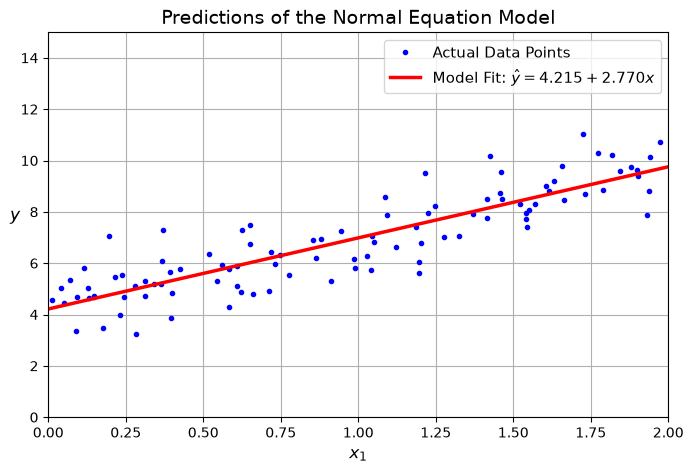

In [4]:
# New instances to predict: x1 = 0 and x1 = 2
X_new = np.array([[0], [2]])
X_new_b = np.c_[np.ones((2, 1)), X_new] # add x0 = 1

# Make prediction: y_hat = X_new_b @ theta_best
y_predict = X_new_b @ theta_best
print("Prediction for x=0:", y_predict[0][0])
print("Prediction for x=2:", y_predict[1][0])

# Plot the regression line over the data
plt.figure(figsize=(8, 5))
plt.plot(X, y, "b.", label="Actual Data Points")
plt.plot(X_new, y_predict, "r-", linewidth=2.5, label="Model Fit: $\\hat{y} = 4.215 + 2.770x$")
plt.xlabel("$x_1$", fontsize=12)
plt.ylabel("$y$", rotation=0, fontsize=12)
plt.title("Predictions of the Normal Equation Model", fontsize=14)
plt.axis([0, 2, 0, 15])
plt.grid(True)
plt.legend(fontsize=11)
plt.show()

🔍 **What this output means & how it reinforces understanding**:
- At $x = 0$, $\hat{y} \approx 4.215$ (which matches our intercept $\theta_0$).
- At $x = 2$, $\hat{y} \approx 4.215 + (2.770 \times 2) \approx 9.755$.
- The red line slices right through the center of the cloud, proving the formula successfully minimized the squared errors.

---
### Step 4: The Scikit-Learn Way (`LinearRegression`)

Does Scikit-Learn do the same thing? Yes, but with a safer, faster algorithm: the **SVD Pseudoinverse**.

In [5]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X, y)

print("Scikit-Learn Intercept (lin_reg.intercept_):", lin_reg.intercept_)
print("Scikit-Learn Slope (lin_reg.coef_):         ", lin_reg.coef_)

# Predictions match our manual calculation
print("\nScikit-Learn Predictions on [0, 2]:\n", lin_reg.predict(X_new))

Scikit-Learn Intercept (lin_reg.intercept_): [4.21509616]
Scikit-Learn Slope (lin_reg.coef_):          [[2.77011339]]

Scikit-Learn Predictions on [0, 2]:
 [[4.21509616]
 [9.75532293]]


In [6]:
# Computing pseudoinverse directly with NumPy: theta = pinv(X_b) @ y
theta_svd = np.linalg.pinv(X_b) @ y
print("Theta from np.linalg.pinv:\n", theta_svd)

Theta from np.linalg.pinv:
 [[4.21509616]
 [2.77011339]]


🔍 **What this output means & how it reinforces understanding**:
- Notice the parameters match the Normal Equation down to the last decimal: `intercept_ = [4.21509616]`, `coef_ = [[2.77011339]]`.
- **Under the hood difference**: Scikit-Learn did **NOT** invert $(X^T X)$. It computed $\mathbf{X}^+ \mathbf{y}$ using `scipy.linalg.lstsq()` (SVD).
- `np.linalg.pinv(X_b) @ y` gives the exact same result. SVD is preferred because it works even if features are collinear (redundant) or $n > m$.

---
### 🧠 The Big Takeaway & Interview Arguments

| Question | What the Code Proved |
| :--- | :--- |
| **"Do both methods yield the same line?"** | Yes! Both the Normal Equation and Scikit-Learn find the exact same global minimum ($\theta_0 \approx 4.215, \theta_1 \approx 2.770$). |
| **"Why does Scikit-Learn use SVD instead of Normal Equation?"** | Normal Equation scales as $\mathcal{O}(n^3)$ and crashes if features are collinear. SVD scales as $\approx \mathcal{O}(n^2)$ and is guaranteed to always work. |
| **"Why do we need Gradient Descent?"** | Both closed-form methods require loading all data into RAM and slow down drastically when $n > 10,000$ features. Gradient Descent (Section 2) solves this by training incrementally! |